Intial Loading of the dataset into dataframe

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv(r"S:\water prediction project ml\water_potability.csv")
df.sample(10)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
1750,7.146117,181.434419,33266.571575,8.381738,373.197146,485.109215,15.469980,52.812932,4.775202,0
1497,8.693150,219.178297,16559.877262,8.877011,355.304980,545.228668,7.283013,73.331529,4.687847,1
1150,5.579517,223.616393,13289.201653,7.698690,368.897034,375.275969,20.224426,104.580881,4.043915,1
784,7.442536,180.859091,18223.027080,8.577250,405.320016,564.793485,14.768337,57.757554,2.191138,1
1449,10.848130,236.725049,14036.163656,9.002885,NaN,564.902813,17.405818,NaN,3.133839,0
304,8.923981,135.938467,27919.770666,12.363285,NaN,415.629484,11.949914,69.314880,4.155583,1
704,6.144759,210.979747,19981.315188,9.203614,271.097104,332.598126,17.187963,79.634242,3.082080,1
2133,7.127711,173.690102,19309.570454,6.533392,372.537225,295.385825,7.273399,88.790927,3.396185,0
1255,6.430255,207.579402,26855.105611,7.087910,304.173434,418.419471,17.921141,34.816398,4.805792,0
41,5.331940,194.874065,16658.876503,7.993830,316.675162,335.120398,10.180514,59.572714,4.434820,0


Feature Engineering

In [22]:
df.describe()
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='str')

In [23]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

filling the missing values

In [24]:
cols = ['ph', 'Sulfate', 'Trihalomethanes']
df[cols] = df[cols].fillna(df[cols].median())
df = df.fillna(df.median(numeric_only=True))
df.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

In [25]:

df["Hardness"].corr(df["Solids"])

np.float64(-0.046899365488177656)

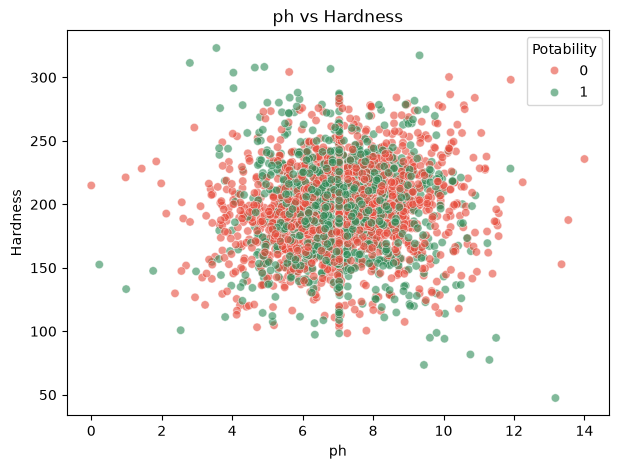

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

data = df

plt.figure(figsize=(7, 5))
sns.scatterplot(data=data, x='ph', y='Hardness', hue='Potability',
                palette={0: '#e74c3c', 1: 'seagreen'}, alpha=0.6)
plt.title('ph vs Hardness')
plt.show()

Outlier Detection

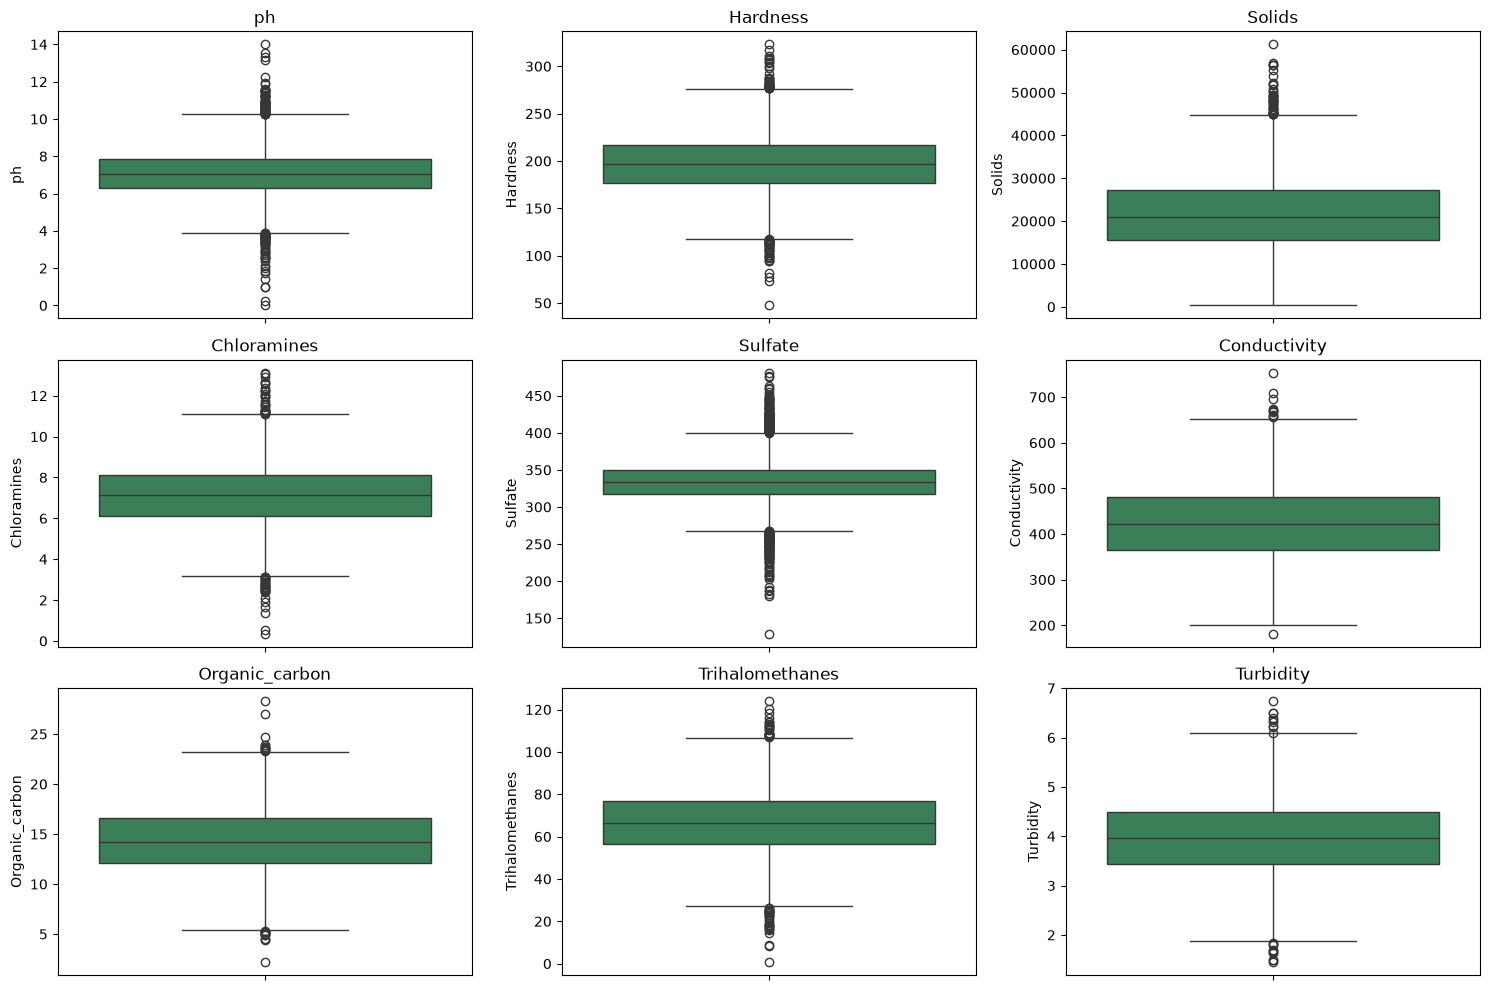

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color='seagreen')
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

Removing Outliers by capping lower and upper boundaries

In [28]:
features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

df_capped = df.copy()

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_capped[col] = df[col].clip(lower=lower, upper=upper)

In [29]:
df_capped.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.036752,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.889107,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


after remove the outlier, how the data distribution looks like

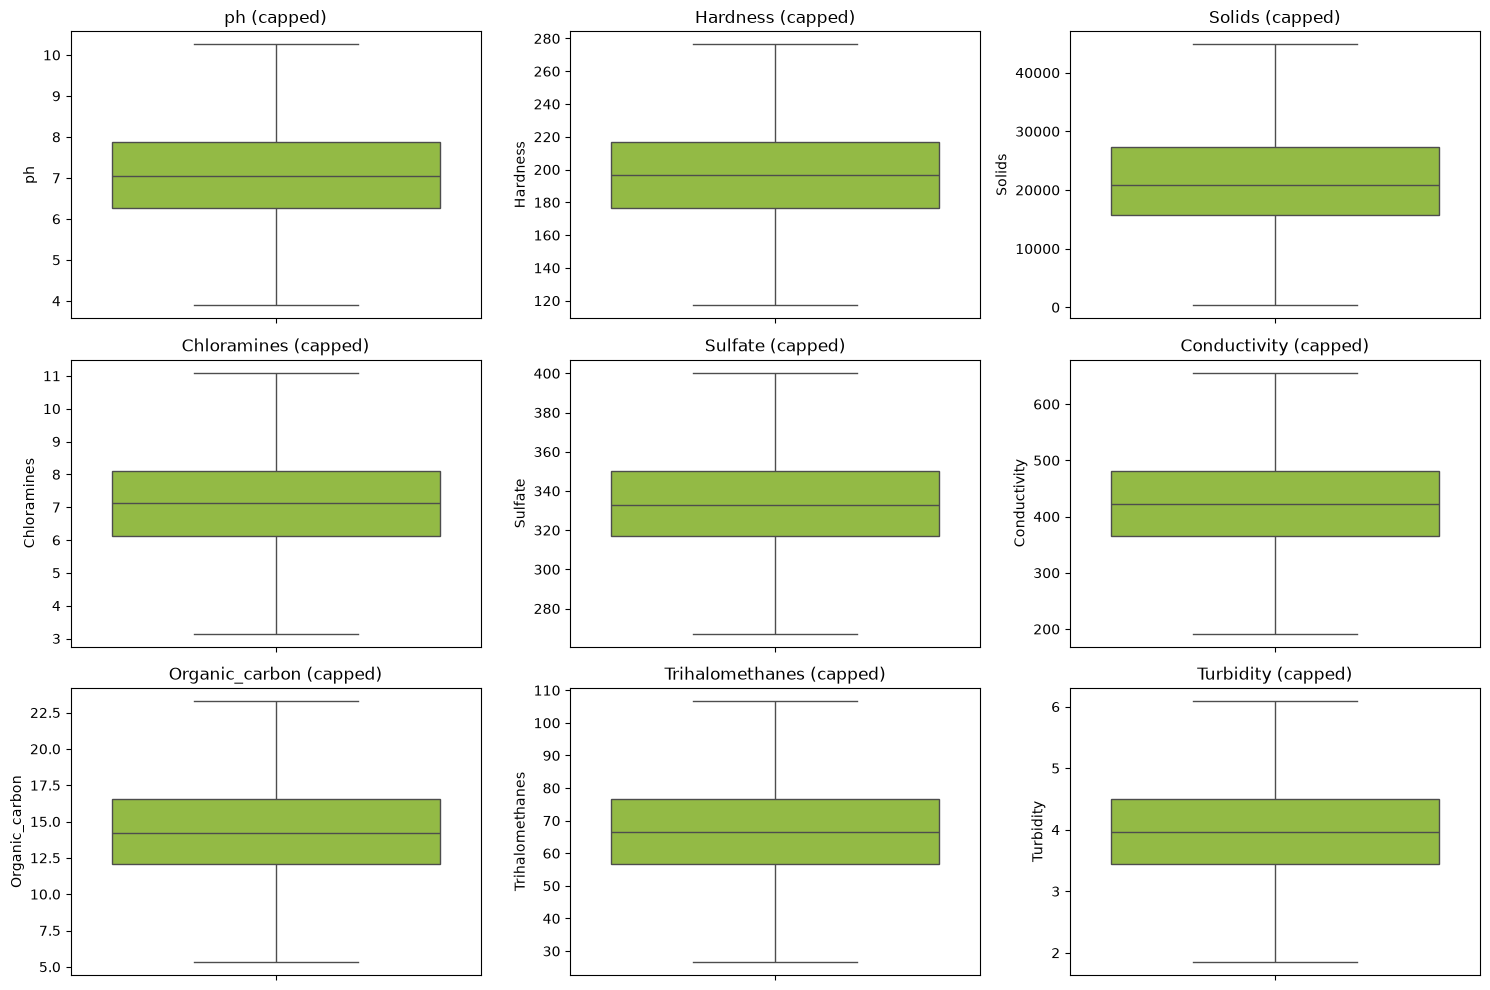

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(y=df_capped[col], ax=axes[i], color='yellowgreen')
    axes[i].set_title(f'{col} (capped)')

plt.tight_layout()
plt.show()

In [31]:
print(df[features].describe().loc[['min', 'max']].sum())
print(df_capped[features].describe().loc[['min', 'max']].sum())

ph                    14.000000
Hardness             370.556000
Solids             61548.138619
Chloramines           13.479000
Sulfate              610.030642
Conductivity         934.826374
Organic_carbon        30.500000
Trihalomethanes      124.738000
Turbidity              8.189000
dtype: float64
ph                    14.147722
Hardness             393.517994
Solids             45152.812484
Chloramines           14.242308
Sulfate              667.480394
Conductivity         847.526719
Organic_carbon        28.623453
Trihalomethanes      133.314265
Turbidity              7.940031
dtype: float64


In [32]:
df_capped.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.036752,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.889107,129.422921,18630.057858,6.635246,333.073546,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.073546,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Checking Skewness of data and transforming it through boxcox and quantile transformation to reduce skewness of Data

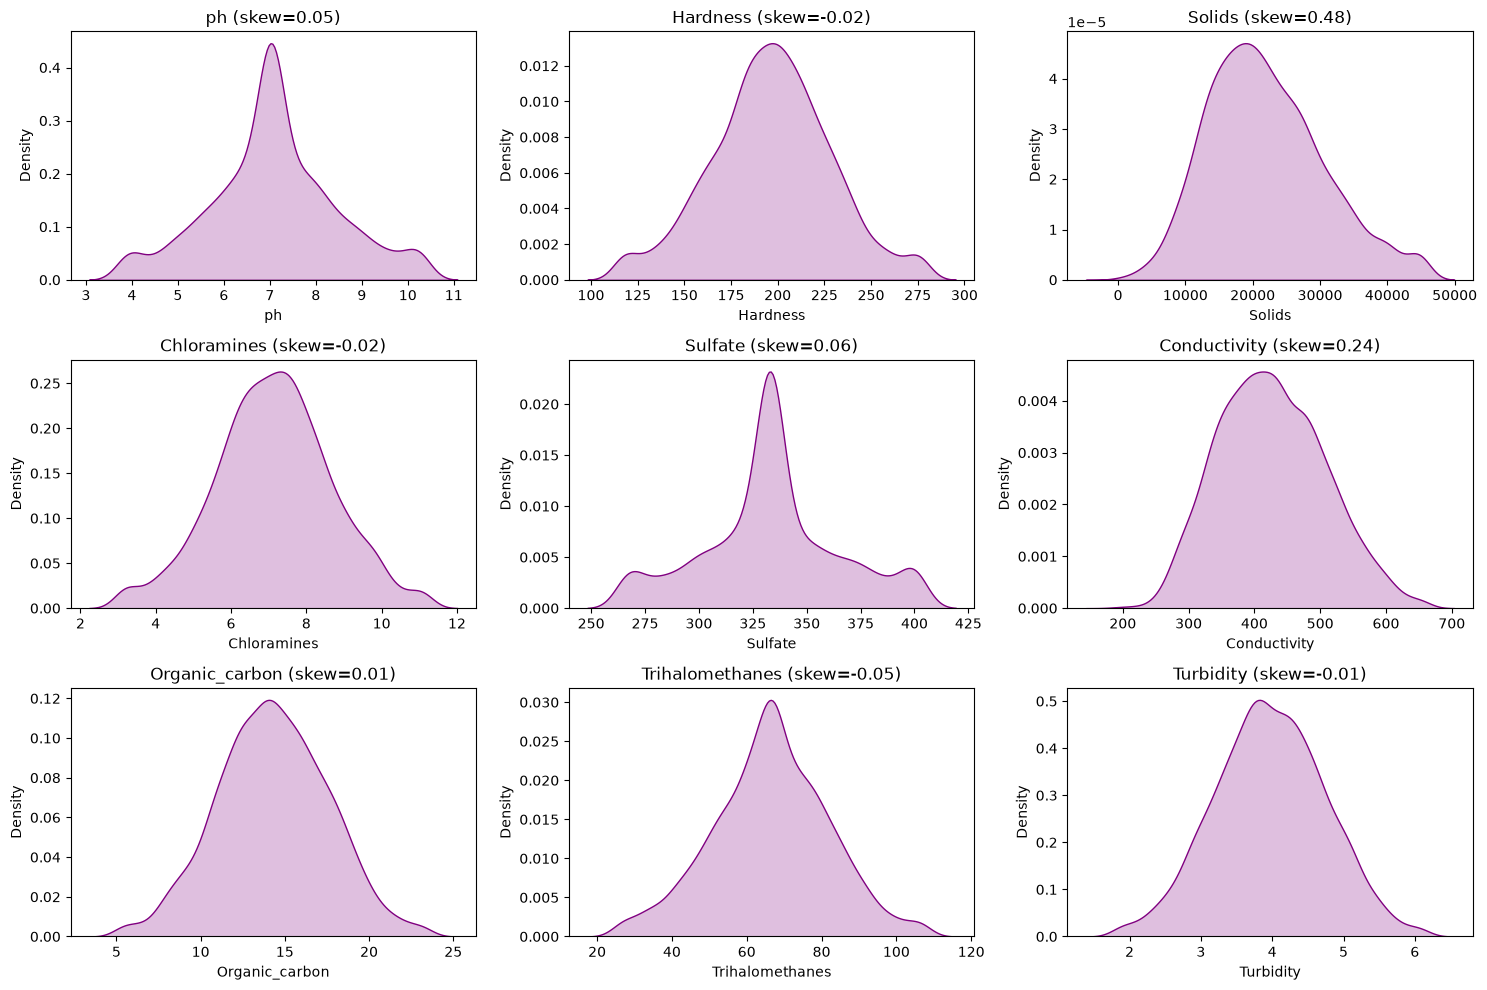

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.kdeplot(df_capped[col], ax=axes[i], fill=True, color='purple')
    axes[i].set_title(f'{col} (skew={df_capped[col].skew():.2f})')

plt.tight_layout()
plt.show()

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

# Box-Cox needs all values > 0
print((df_capped[features] <= 0).sum())

# 1) Box-Cox
pt = PowerTransformer(method='box-cox', standardize=True)
df_boxcox = df_capped.copy()
df_boxcox[features] = pt.fit_transform(df_capped[features])

# 2) Quantile transform (to a normal distribution)
qt = QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=42)
df_quantile = df_capped.copy()
df_quantile[features] = qt.fit_transform(df_capped[features])

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
dtype: int64


Check Skewness after Data transformation

In [35]:
skew_table = pd.DataFrame({
    'Capped': df_capped[features].skew(),
    'Box-Cox': df_boxcox[features].skew(),
    'Quantile': df_quantile[features].skew()
})
print(skew_table.round(3))

# Box-Cox lambda for each column
print(dict(zip(features, pt.lambdas_.round(3))))

                 Capped  Box-Cox  Quantile
ph                0.055    0.004     0.105
Hardness         -0.025    0.001    -0.095
Solids            0.485    0.003     1.077
Chloramines      -0.018   -0.002    -0.022
Sulfate           0.056   -0.001     0.042
Conductivity      0.241   -0.012     0.267
Organic_carbon    0.009   -0.011    -0.028
Trihalomethanes  -0.052   -0.007    -0.093
Turbidity        -0.014   -0.014    -0.029
{'ph': np.float64(0.92), 'Hardness': np.float64(1.05), 'Solids': np.float64(0.568), 'Chloramines': np.float64(1.023), 'Sulfate': np.float64(0.798), 'Conductivity': np.float64(0.436), 'Organic_carbon': np.float64(0.971), 'Trihalomethanes': np.float64(1.062), 'Turbidity': np.float64(1.001)}


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.kdeplot(df_quantile[col], ax=axes[i], fill=True, color='brown')
    axes[i].set_title(f'{col} (skew={df_quantile[col].skew():.2f})')

plt.tight_layout()
plt.show()

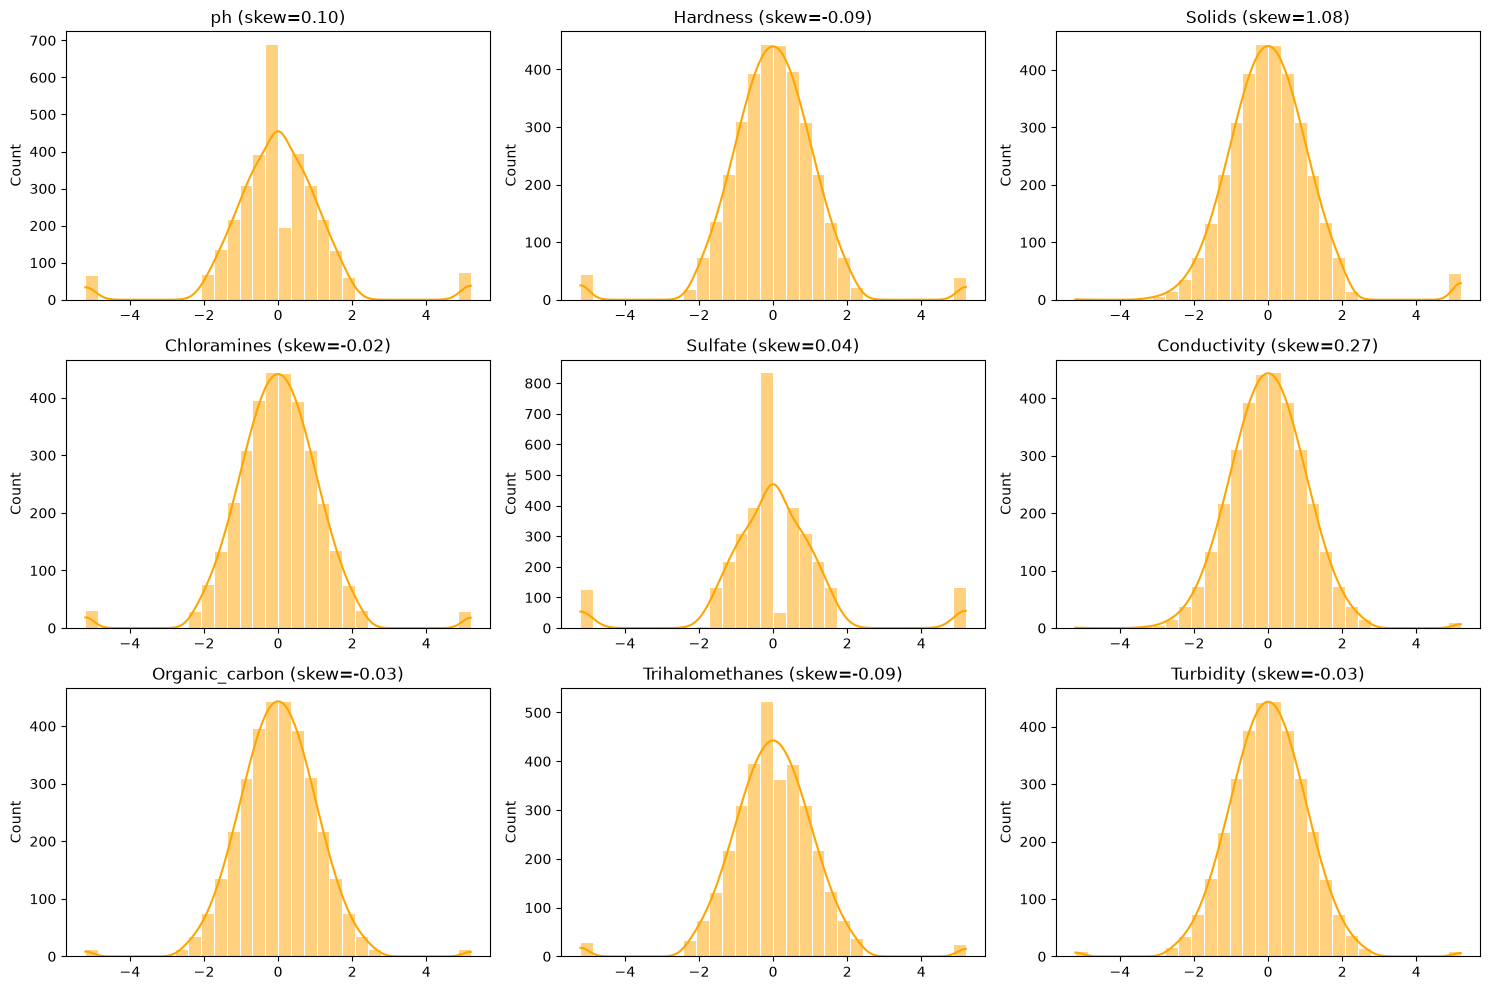

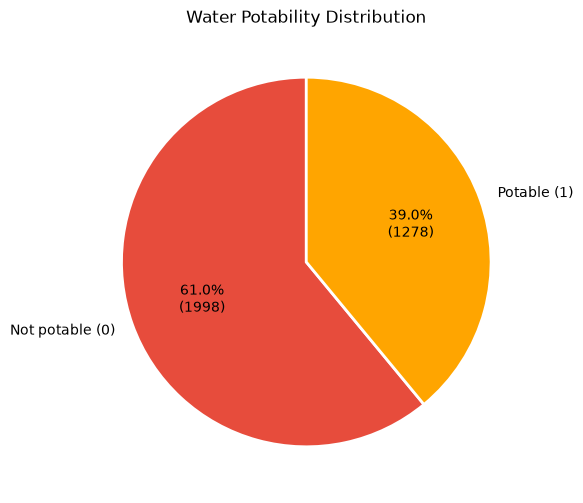

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df_quantile[col], bins=30, kde=True,
                 color='orange', edgecolor='white', ax=axes[i])
    axes[i].set_title(f'{col} (skew={df_quantile[col].skew():.2f})')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

target = 'Potability'
data = df_quantile if target in df_quantile.columns else df   # fallback

counts = data[target].value_counts().sort_index()
labels = ['Not potable (0)' if k == 0 else 'Potable (1)' for k in counts.index]

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=labels, autopct=lambda p: f'{p:.1f}%\n({int(round(p * counts.sum() / 100))})',
        colors=['#e74c3c', 'orange'], startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
plt.title('Water Potability Distribution')
plt.show()

In [38]:
from sklearn.model_selection import train_test_split

features = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate',
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

X = df_quantile[features]
y = df_quantile["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('X_train:', X_train.shape, ' X_test:', X_test.shape)
print('Train class ratio:\n', y_train.value_counts(normalize=True).round(3))
print('Test class ratio:\n', y_test.value_counts(normalize=True).round(3))

X_train: (2620, 9)  X_test: (656, 9)
Train class ratio:
 Potability
0    0.61
1    0.39
Name: proportion, dtype: float64
Test class ratio:
 Potability
0    0.61
1    0.39
Name: proportion, dtype: float64


    PC  Explained_var  Cumulative
0  PC1         0.1345      0.1345
1  PC2         0.1234      0.2579
2  PC3         0.1179      0.3758
3  PC4         0.1122      0.4880
4  PC5         0.1102      0.5982
5  PC6         0.1081      0.7063
6  PC7         0.1046      0.8109
7  PC8         0.1015      0.9124
8  PC9         0.0876      1.0000
Components for 90% variance: 8
Components for 95% variance: 9


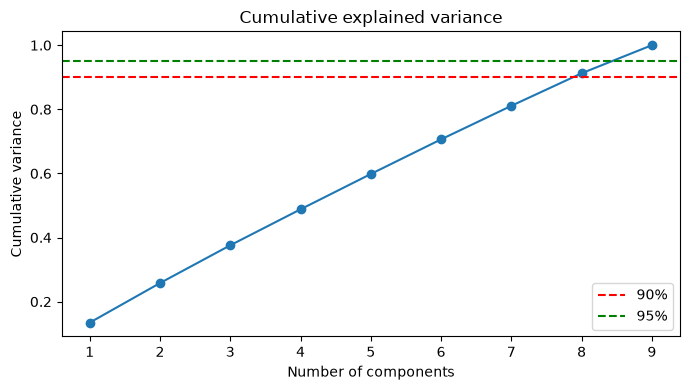

Reduced shape: (2620, 9) (656, 9)


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

prep = Pipeline([
    ('imp', SimpleImputer(strategy='median')),   
    ('scaler', StandardScaler())
])
X_train_s = prep.fit_transform(X_train)
X_test_s  = prep.transform(X_test)

pca = PCA(random_state=42)
pca.fit(X_train_s)

# 2. Explained variance table
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
var_df = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(evr))],
    'Explained_var': evr.round(4),
    'Cumulative': cum.round(4)
})
print(var_df)
print('Components for 90% variance:', np.argmax(cum >= 0.90) + 1)
print('Components for 95% variance:', np.argmax(cum >= 0.95) + 1)

# 3. Cumulative explained variance plot (the only plot)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum, 'o-')
plt.axhline(0.90, ls='--', color='r', label='90%')
plt.axhline(0.95, ls='--', color='g', label='95%')
plt.xlabel('Number of components')
plt.ylabel('Cumulative variance')
plt.title('Cumulative explained variance')
plt.xticks(range(1, len(cum) + 1))
plt.legend()
plt.tight_layout()
plt.show()

# 4. Reduce to 95% variance (fit on train only)
pca_95 = PCA(n_components=0.95, random_state=42).fit(X_train_s)
X_train_pca = pca_95.transform(X_train_s)
X_test_pca  = pca_95.transform(X_test_s)
print('Reduced shape:', X_train_pca.shape, X_test_pca.shape)

Use of three ML algorithms: i) RandomForest Classifier ii) GradientBoosting Classifier iii) XGBoosting Classifier

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_score, StratifiedKFold


from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             precision_score, recall_score,
                             classification_report, RocCurveDisplay)
#we build here randomforest
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestClassifier(
    n_estimators=600,
    max_depth=14,
    min_samples_split=9,
    min_samples_leaf=2,
    max_features='log2',
    max_samples=0.899,
    class_weight='balanced_subsample',
    ccp_alpha=1.4,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Gradient Boosting
gb = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    subsample=0.8,
    max_features='sqrt',
    random_state=42
)

#  XGBoost
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=neg / pos,   
    tree_method='hist',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

models = {'Random Forest': rf, 'Gradient Boosting': gb, 'XGBoost': xgb}


rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring='roc_auc', n_jobs=-1).mean()
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    print(f'\n=== {name} ===')
    print(classification_report(y_test, pred, digits=3))

    rows.append({
        'Model': name,
        'CV_AUC': cv_auc,
        'Test_AUC': roc_auc_score(y_test, proba),
        'Accuracy': accuracy_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
    })




=== Random Forest ===
              precision    recall  f1-score   support

           0      0.000     0.000     0.000       400
           1      0.390     1.000     0.561       256

    accuracy                          0.390       656
   macro avg      0.195     0.500     0.281       656
weighted avg      0.152     0.390     0.219       656



c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag


=== Gradient Boosting ===
              precision    recall  f1-score   support

           0      0.655     0.900     0.758       400
           1      0.623     0.258     0.365       256

    accuracy                          0.649       656
   macro avg      0.639     0.579     0.561       656
weighted avg      0.642     0.649     0.604       656


=== XGBoost ===
              precision    recall  f1-score   support

           0      0.676     0.720     0.697       400
           1      0.513     0.461     0.486       256

    accuracy                          0.619       656
   macro avg      0.595     0.590     0.591       656
weighted avg      0.612     0.619     0.615       656



In [41]:
print(type(rf))
print(hasattr(rf, "feature_importances_"))
print(len(rf.feature_importances_), len(features))



<class 'sklearn.ensemble._forest.RandomForestClassifier'>
True
9 9


Nodes in first tree: 455
Test accuracy: 0.6783536585365854


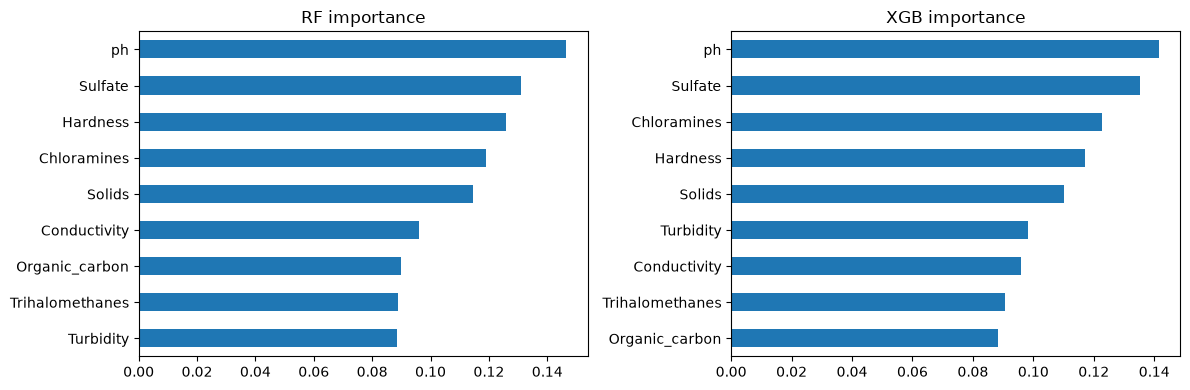

In [42]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("Nodes in first tree:", rf.estimators_[0].tree_.node_count)   # should be well above 1
print("Test accuracy:", rf.score(X_test, y_test))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(rf.feature_importances_, index=features).sort_values().plot.barh(ax=ax[0], title='RF importance')
pd.Series(xgb.feature_importances_, index=features).sort_values().plot.barh(ax=ax[1], title='XGB importance')
plt.tight_layout(); plt.show()

In [43]:
rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring='roc_auc', n_jobs=-1).mean()
    model.fit(X_train, y_train)

    # Train and test predictions
    train_pred = model.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)

    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_acc = accuracy_score(y_test, pred)

    print(f'\n=== {name} ===')
    print(f'Train accuracy: {train_acc:.3f}')
    print(f'Test accuracy:  {test_acc:.3f}')
    print(f'Gap (train - test): {train_acc - test_acc:.3f}')
    print(classification_report(y_test, pred, digits=3))

    rows.append({
        'Model': name,
        'CV_AUC': cv_auc,
        'Test_AUC': roc_auc_score(y_test, proba),
        'Train_Acc': train_acc,
        'Test_Acc': test_acc,
        'F1': f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
    })

res_df = pd.DataFrame(rows).set_index('Model').round(3)
print(res_df)


=== Random Forest ===
Train accuracy: 0.610
Test accuracy:  0.390
Gap (train - test): 0.220
              precision    recall  f1-score   support

           0      0.000     0.000     0.000       400
           1      0.390     1.000     0.561       256

    accuracy                          0.390       656
   macro avg      0.195     0.500     0.281       656
weighted avg      0.152     0.390     0.219       656



c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag


=== Gradient Boosting ===
Train accuracy: 0.811
Test accuracy:  0.649
Gap (train - test): 0.162
              precision    recall  f1-score   support

           0      0.655     0.900     0.758       400
           1      0.623     0.258     0.365       256

    accuracy                          0.649       656
   macro avg      0.639     0.579     0.561       656
weighted avg      0.642     0.649     0.604       656


=== XGBoost ===
Train accuracy: 0.944
Test accuracy:  0.619
Gap (train - test): 0.325
              precision    recall  f1-score   support

           0      0.676     0.720     0.697       400
           1      0.513     0.461     0.486       256

    accuracy                          0.619       656
   macro avg      0.595     0.590     0.591       656
weighted avg      0.612     0.619     0.615       656

                   CV_AUC  Test_AUC  Train_Acc  Test_Acc     F1  Precision  \
Model                                                                        
Random

In [44]:
import pickle
pickle.dump(rf, open("random_forest_model.pkl", "wb"))
pickle.dump(gb, open("gradient_boosting_model.pkl", "wb"))
pickle.dump(xgb, open("xgboost_model.pkl", "wb"))
pickle.dump(res_df, open("model_results.pkl", "wb"))